In [2]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import random
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report

In [3]:
train_transform = transforms.Compose([
    transforms.Resize((228,228)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize((228,228)),
    transforms.ToTensor()
])

train_path = '/kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train'
test_path  = '/kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test'

train_data = datasets.ImageFolder(root=train_path, transform=train_transform)
test_data  = datasets.ImageFolder(root=test_path, transform = test_transform)

print(f'Klasslar: {train_data.classes}')

Klasslar: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [4]:
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_data, batch_size=128, shuffle=False)

In [12]:
model = nn.Sequential(
    nn.Conv2d(3, 32, 3, 1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),
    nn.Dropout(0.1),

    nn.Conv2d(32, 64, 3, 1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),
    nn.Dropout(0.2),

    nn.Conv2d(64,128, 3, 1),
    nn.BatchNorm2d(128),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),
    nn.Dropout(0.3),

    nn.Conv2d(128, 256, 3, 1),
    nn.BatchNorm2d(256),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),
    nn.Dropout(0.4),

    nn.Conv2d(256, 512, 3, 1),
    nn.BatchNorm2d(512),
    nn.ReLU(),
    nn.MaxPool2d(2,2),
    nn.Dropout(0.5),
    
    nn.Flatten(),
    
    nn.Linear(5 * 5 * 512, 1024),
    nn.ReLU(),
    nn.Dropout(0.35),

    nn.Linear(1024, 512),
    nn.ReLU(),
    nn.Dropout(0.25),

    nn.Linear(512, 128),
    nn.ReLU(),
    nn.Dropout(0.15),

    nn.Linear(128, 6)
    
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

In [15]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

In [16]:
for i in range(1,9):
    model.train()
    correct = 0
    train_size = 0
    running_loss = 0
    for images, target in train_loader:
        images = images.to(device)
        target = target.to(device)

        y_pred = model(images)
        loss = criterion(y_pred, target)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        train_size += target.size(0)
        correct += (y_pred.argmax(dim=1) == target).sum().item()

    print(f"|Epoch:{i}|Loss:{(running_loss / len(train_loader)):.2f}|Acc:{((correct / train_size)*100):.2f}%|")

|Epoch:1|Loss:1.24|Acc:48.42%|
|Epoch:2|Loss:0.85|Acc:67.45%|
|Epoch:3|Loss:0.70|Acc:74.70%|
|Epoch:4|Loss:0.63|Acc:78.09%|
|Epoch:5|Loss:0.57|Acc:79.66%|
|Epoch:6|Loss:0.52|Acc:81.51%|
|Epoch:7|Loss:0.51|Acc:81.87%|
|Epoch:8|Loss:0.48|Acc:83.23%|


In [22]:
model.eval()
correct = []
predict = []
with torch.no_grad():
    for images, target in test_loader:
        images = images.to(device)
        target = target.to(device)

        y_pred = model(images)
        correct.extend(target.cpu().numpy())
        predict.extend((y_pred.argmax(dim=1)).cpu().numpy())

print(classification_report(correct, predict))

              precision    recall  f1-score   support

           0       0.80      0.84      0.82       437
           1       0.79      0.98      0.87       474
           2       0.91      0.52      0.66       553
           3       0.66      0.89      0.76       525
           4       0.75      0.85      0.80       510
           5       0.91      0.63      0.74       501

    accuracy                           0.78      3000
   macro avg       0.80      0.79      0.78      3000
weighted avg       0.80      0.78      0.77      3000



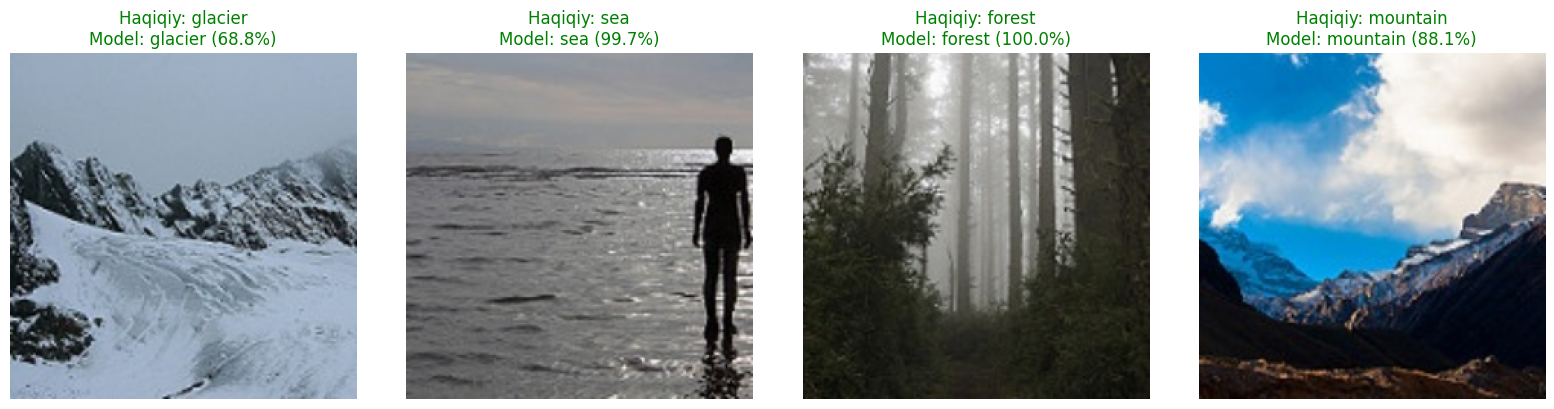

In [23]:
class_names = test_data.classes
mean = torch.tensor([0.0, 0.0, 0.0]).view(3, 1, 1)
std = torch.tensor([1.0, 1.0, 1.0]).view(3, 1, 1)

model.eval()
indices = random.sample(range(len(test_data)), 4)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

with torch.no_grad():
    for ax, idx in zip(axes, indices):
        image, label = test_data[idx]
        output = model(image.unsqueeze(0).to(device))
        probs = torch.softmax(output, dim=1)
        conf, pred = probs.max(dim=1)
        img = (image * std + mean).clamp(0, 1)
        ax.imshow(img.permute(1, 2, 0).numpy())
        ax.axis("off")
        pred_name = class_names[pred.item()]
        true_name = class_names[label]
        color = "green" if pred.item() == label else "red"
        ax.set_title(
            f"Haqiqiy: {true_name}\nModel: {pred_name} ({conf.item()*100:.1f}%)",
            color=color)
plt.tight_layout()
plt.show()
